# Phase 1 — Data Preparation

Implements Chapter 3, Section 3.2 (Table 3.1) and Chapter 4, Section 4.3 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"*.

**Steps covered in this notebook:**
1. Load the raw Kaggle dataset
2. Verify missing values and data types
3. Enforce chronological ordering
4–5. Identify the target variable and separate predictors
6. Remove identifier columns (timestamp retained for ordering only)
7. Report global correlation / VIF as descriptive diagnostics only
8. Define the candidate feature set (**excluding two target-leakage variables identified below**)
9. Create the temporally ordered train/test split

Visualisations of the target distribution, its behaviour over time, feature correlations,
and feature distributions are included throughout to support Chapter 5's dataset
characterisation.

**Output:** `data/processed/smart_grid_clean.csv`, plus diagnostic tables and figures in
`results/tables/` and `results/figures/` consumed by Chapter 5.

In [20]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
   PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/dissertation-project


In [21]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import data_utils as du

RAW_PATH = os.path.join(PROJECT_ROOT, 'data', 'raw', 'smart_grid_dataset.csv')
PROCESSED_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'smart_grid_clean.csv')
TABLES_DIR = os.path.join(PROJECT_ROOT, 'results', 'tables')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'results', 'figures')
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Step 1: load
df_raw = du.load_raw_data(RAW_PATH)
print(f'Loaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
df_raw.head()

Loaded 50,000 rows x 16 columns


,Timestamp,Voltage (V),Current (A),Power Consumption (kW),Reactive Power (kVAR),Power Factor,Solar Power (kW),Wind Power (kW),Grid Supply (kW),Voltage Fluctuation (%),Overload Condition,Transformer Fault,Temperature (°C),Humidity (%),Electricity Price (USD/kWh),Predicted Load (kW)
0,2024-01-01 00:00:00,232.483571,5.124673,1.191402,0.399029,0.907766,46.614845,26.399566,0.0,1.055937,0,0,17.842767,64.523353,0.416156,1.233158
1,2024-01-01 00:15:00,229.308678,22.213519,5.093753,1.248030,0.831813,6.907170,18.555011,0.0,-3.910902,1,0,18.753698,49.671940,0.492334,5.247824
2,2024-01-01 00:30:00,233.238443,46.132217,10.759806,2.790464,0.999005,15.477640,12.905025,0.0,-0.197551,0,0,16.719325,48.472769,0.427785,10.580278
3,2024-01-01 00:45:00,237.615149,47.648972,11.322118,1.956965,0.896462,35.746398,28.937129,0.0,2.671921,0,0,15.364564,75.766776,0.487953,11.225946
4,2024-01-01 01:00:00,228.829233,7.410166,1.695663,0.624718,0.870681,27.555038,14.184648,0.0,3.826937,0,0,38.760333,61.384213,0.290078,1.696639


## Step 2: Missing values and data types

In [23]:
summary = du.inspect_data(df_raw)
summary.to_csv(os.path.join(TABLES_DIR, 'phase1_data_summary.csv'))
summary

,dtype,n_missing,pct_missing,n_unique
Timestamp,object,0,0.0,50000
Voltage (V),float64,0,0.0,50000
Current (A),float64,0,0.0,50000
Power Consumption (kW),float64,0,0.0,50000
Reactive Power (kVAR),float64,0,0.0,50000
Power Factor,float64,0,0.0,50000
Solar Power (kW),float64,0,0.0,50000
Wind Power (kW),float64,0,0.0,50000
Grid Supply (kW),float64,0,0.0,814
Voltage Fluctuation (%),float64,0,0.0,50000


In [24]:
n_missing_total = int(df_raw.isna().sum().sum())
n_dupes_total = int(df_raw.duplicated().sum())
print(f'Total missing cells: {n_missing_total}')
print(f'Fully duplicated rows: {n_dupes_total}')
assert n_missing_total == 0, "Unexpected missing values -- handle before proceeding."


Total missing cells: 0
Fully duplicated rows: 0


### Visualisation: target variable distribution

Shape of `Predicted Load (kW)` before any splitting -- checked for skew, outliers, and plausible range.

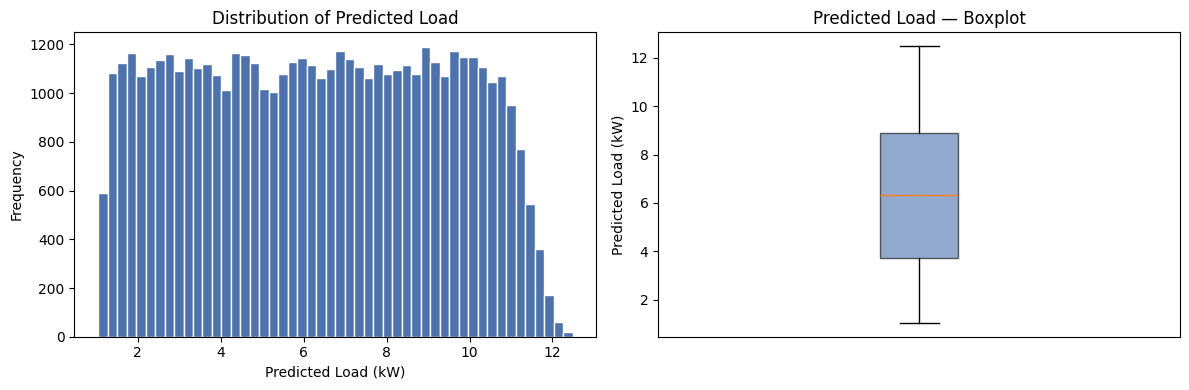

count    50000.000000
mean         6.320693
std          2.997199
min          1.043487
25%          3.711469
50%          6.328723
75%          8.910125
max         12.483253
Name: Predicted Load (kW), dtype: float64


In [25]:
target = du.TARGET_COL
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_raw[target], bins=50, color='#4C72B0', edgecolor='white')
axes[0].set_xlabel('Predicted Load (kW)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Predicted Load')

axes[1].boxplot(df_raw[target], vert=True, patch_artist=True,
                 boxprops=dict(facecolor='#4C72B0', alpha=0.6))
axes[1].set_ylabel('Predicted Load (kW)')
axes[1].set_title('Predicted Load — Boxplot')
axes[1].set_xticks([])

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'phase1_target_distribution.png'), dpi=150)
plt.show()

print(df_raw[target].describe())

## Step 3: Enforce chronological ordering

In [26]:
df = du.enforce_chronological_order(df_raw, timestamp_col=du.TIMESTAMP_COL)
print('Time range:', df[du.TIMESTAMP_COL].min(), '→', df[du.TIMESTAMP_COL].max())
print('Is monotonically increasing:', df[du.TIMESTAMP_COL].is_monotonic_increasing)

# Infer and report the sampling interval (used later to justify window sizes in Section 3.4)
intervals = df[du.TIMESTAMP_COL].diff().dropna().value_counts()
print('\nSampling interval(s) observed:')
print(intervals)

Time range: 2024-01-01 00:00:00 → 2025-06-04 19:45:00
Is monotonically increasing: True

Sampling interval(s) observed:
Timestamp
0 days 00:15:00    49999
Name: count, dtype: int64


### Visualisation: target variable over time

The full series (resampled to a daily mean, since the raw series is 50,000 points at 15-minute resolution) alongside a one-week zoomed window, to give a sense of both the long-run and short-run behaviour that the dynamic framework needs to track.

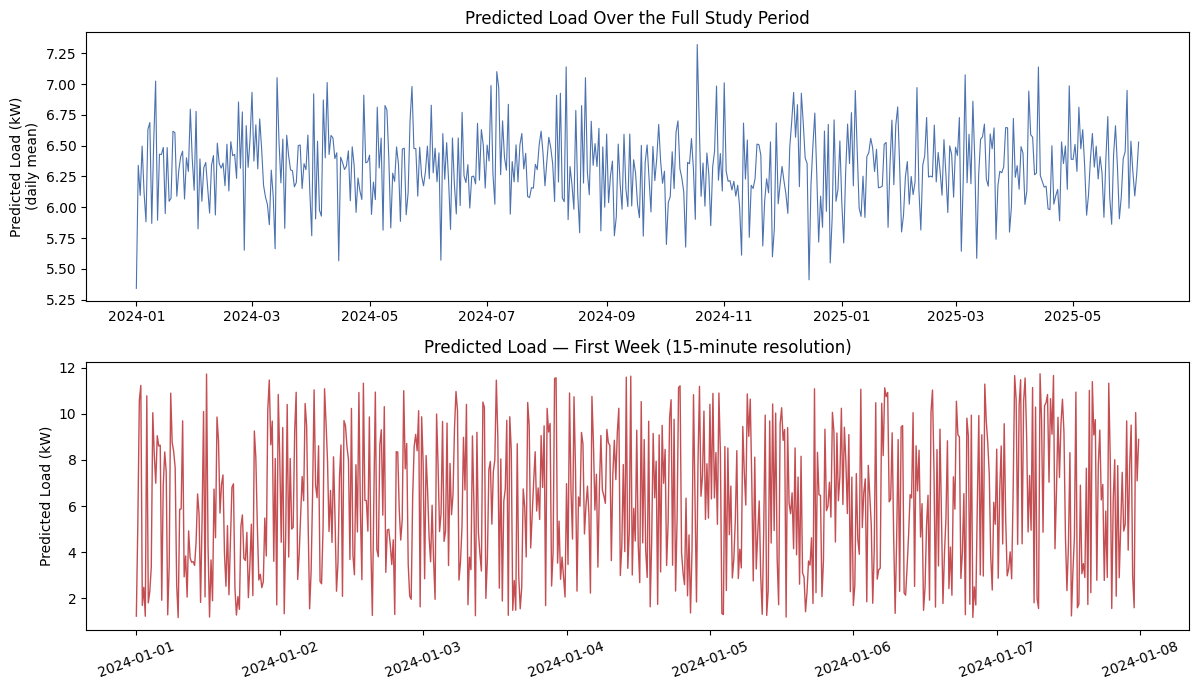

In [27]:
ts = df.set_index(du.TIMESTAMP_COL)[target]

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

daily_mean = ts.resample('D').mean()
axes[0].plot(daily_mean.index, daily_mean.values, color='#4C72B0', linewidth=0.8)
axes[0].set_ylabel('Predicted Load (kW)\n(daily mean)')
axes[0].set_title('Predicted Load Over the Full Study Period')

one_week = ts.iloc[:7 * 96]  # 96 readings/day at 15-minute resolution
axes[1].plot(one_week.index, one_week.values, color='#C44E52', linewidth=1.0)
axes[1].set_ylabel('Predicted Load (kW)')
axes[1].set_title('Predicted Load — First Week (15-minute resolution)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'phase1_target_over_time.png'), dpi=150)
plt.show()

## Steps 4–6: Target, identifiers, and target-leakage check

Before finalising the candidate feature set, every non-target column is checked for
target leakage: a candidate feature is treated as a leakage suspect if its correlation
with the target exceeds ~0.98, since a genuine forecasting feature should not be
near-perfectly determined by (or determining of) the target at the same timestamp.

In [28]:
all_predictor_cols = [c for c in df.columns if c not in [du.TARGET_COL, du.TIMESTAMP_COL]]
leakage_check = du.compute_correlation_with_target(df, all_predictor_cols, du.TARGET_COL)
leakage_check.to_csv(os.path.join(TABLES_DIR, 'phase1_target_correlation.csv'))
leakage_check

,Predicted Load (kW)
Power Consumption (kW),0.997735
Current (A),0.996473
Reactive Power (kVAR),0.776570
Grid Supply (kW),0.094707
Voltage (V),0.043304
Electricity Price (USD/kWh),0.004825
Voltage Fluctuation (%),0.001908
Transformer Fault,0.000959
Humidity (%),0.000531
Overload Condition,0.000524


In [29]:
SUSPECT_THRESHOLD = 0.98
suspects = leakage_check[leakage_check.abs() > SUSPECT_THRESHOLD]
print('Leakage suspects (|corr| > 0.98):')
print(suspects)
print()
print('Confirmed leakage columns (Chapter 4, Section 4.3):', du.LEAKAGE_COLUMNS)
assert set(suspects.index) == set(du.LEAKAGE_COLUMNS), (
    "The empirically-flagged leakage suspects no longer match LEAKAGE_COLUMNS in "
    "data_utils.py -- update the constant (and Chapter 4's text) if this dataset "
    "version differs from the one the methodology was written against."
)

Leakage suspects (|corr| > 0.98):
Power Consumption (kW)    0.997735
Current (A)               0.996473
Name: Predicted Load (kW), dtype: float64

Confirmed leakage columns (Chapter 4, Section 4.3): ['Power Consumption (kW)', 'Current (A)']


### Visualisation: correlation of every candidate predictor with the target

Leakage suspects (Power Consumption, Current) shown in red for contrast against the twelve genuine candidate features.

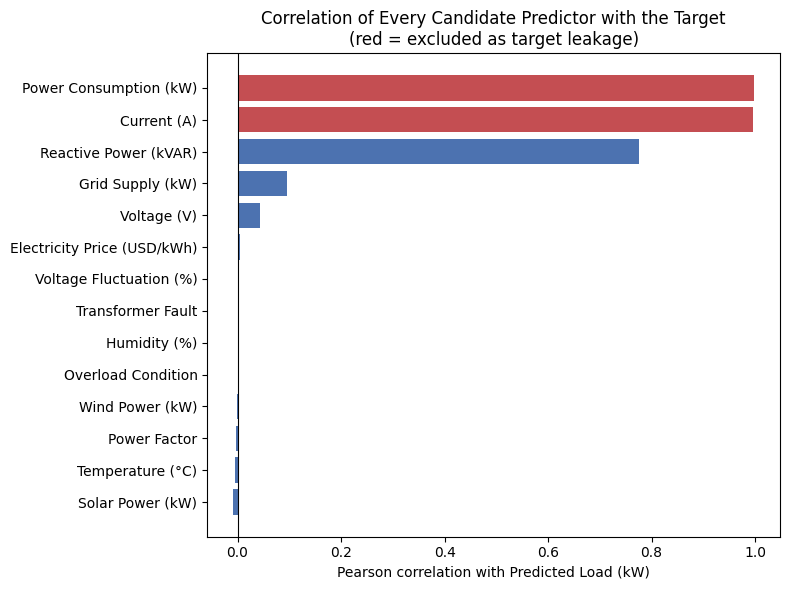

In [30]:
colors = ['#C44E52' if f in du.LEAKAGE_COLUMNS else '#4C72B0' for f in leakage_check.index]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(leakage_check.index[::-1], leakage_check.values[::-1], color=colors[::-1])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson correlation with Predicted Load (kW)')
ax.set_title('Correlation of Every Candidate Predictor with the Target\n(red = excluded as target leakage)')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'phase1_target_correlation.png'), dpi=150)
plt.show()

## Step 7: Descriptive diagnostics only — correlation and VIF

In [31]:
corr_matrix = du.compute_correlation_matrix(df, du.CANDIDATE_FEATURES)
corr_matrix.to_csv(os.path.join(TABLES_DIR, 'phase1_correlation_matrix.csv'))
corr_matrix.round(2)

,Voltage (V),Reactive Power (kVAR),Power Factor,Solar Power (kW),Wind Power (kW),Grid Supply (kW),Voltage Fluctuation (%),Overload Condition,Transformer Fault,Temperature (°C),Humidity (%),Electricity Price (USD/kWh)
Voltage (V),1.00,0.03,-0.00,0.01,-0.01,-0.00,0.01,0.00,-0.00,0.00,-0.00,0.00
Reactive Power (kVAR),0.03,1.00,-0.01,-0.01,-0.00,0.08,0.01,-0.00,0.00,-0.00,-0.00,0.01
Power Factor,-0.00,-0.01,1.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.01,-0.00,0.00,0.00
Solar Power (kW),0.01,-0.01,-0.00,1.00,0.00,-0.16,0.00,0.01,-0.01,0.00,-0.00,-0.01
Wind Power (kW),-0.01,-0.00,-0.00,0.00,1.00,-0.15,-0.00,0.01,-0.00,0.01,-0.00,0.00
Grid Supply (kW),-0.00,0.08,0.00,-0.16,-0.15,1.00,-0.01,-0.01,0.01,0.00,-0.01,0.00
Voltage Fluctuation (%),0.01,0.01,-0.00,0.00,-0.00,-0.01,1.00,0.00,0.00,-0.00,0.00,0.00
Overload Condition,0.00,-0.00,-0.00,0.01,0.01,-0.01,0.00,1.00,-0.00,0.00,0.00,-0.00
Transformer Fault,-0.00,0.00,-0.01,-0.01,-0.00,0.01,0.00,-0.00,1.00,0.00,-0.00,-0.00
Temperature (°C),0.00,-0.00,-0.00,0.00,0.01,0.00,-0.00,0.00,0.00,1.00,-0.00,-0.01


### Visualisation: correlation heatmap (candidate features only)

Descriptive only, consistent with Section 3.2 — not used to eliminate any feature here.

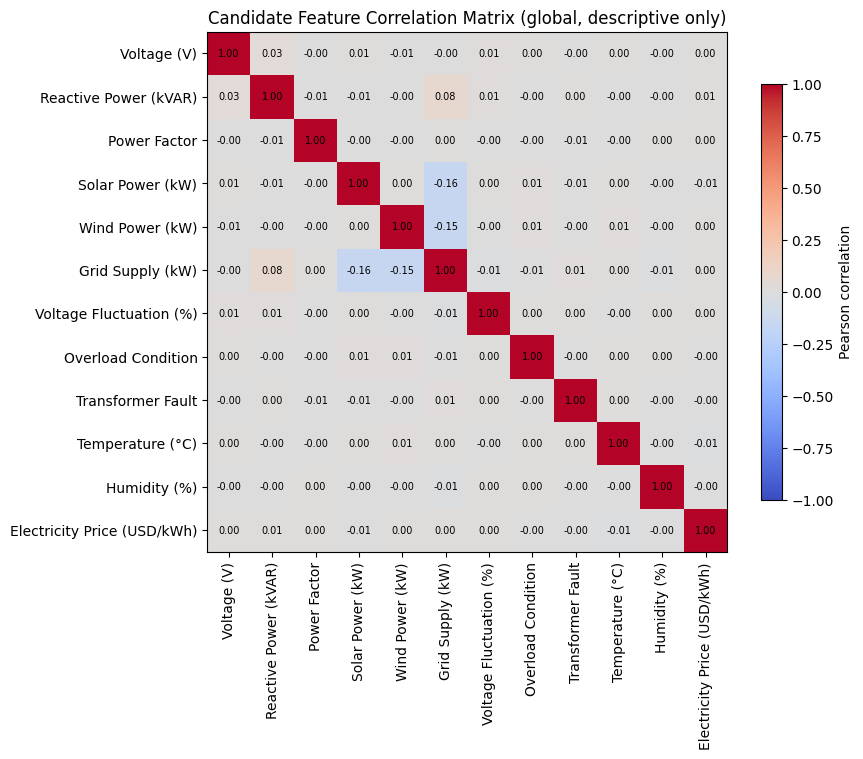

In [32]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr_matrix.values, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(du.CANDIDATE_FEATURES)))
ax.set_xticklabels(du.CANDIDATE_FEATURES, rotation=90)
ax.set_yticks(range(len(du.CANDIDATE_FEATURES)))
ax.set_yticklabels(du.CANDIDATE_FEATURES)

for i in range(len(du.CANDIDATE_FEATURES)):
    for j in range(len(du.CANDIDATE_FEATURES)):
        ax.text(j, i, f'{corr_matrix.values[i, j]:.2f}', ha='center', va='center', fontsize=7)

fig.colorbar(im, ax=ax, label='Pearson correlation', shrink=0.8)
ax.set_title('Candidate Feature Correlation Matrix (global, descriptive only)')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'phase1_correlation_heatmap.png'), dpi=150)
plt.show()

In [33]:
vif_table = du.compute_vif(df, du.CANDIDATE_FEATURES)
vif_table.to_csv(os.path.join(TABLES_DIR, 'phase1_vif.csv'), index=False)
vif_table

,feature,VIF
0,Grid Supply (kW),1.058054
1,Solar Power (kW),1.027725
2,Wind Power (kW),1.024173
3,Reactive Power (kVAR),1.007399
4,Voltage (V),1.001367
5,Temperature (°C),1.000374
6,Voltage Fluctuation (%),1.000371
7,Overload Condition,1.000309
8,Electricity Price (USD/kWh),1.000226
9,Humidity (%),1.000207


### Visualisation: Variance Inflation Factor per candidate feature

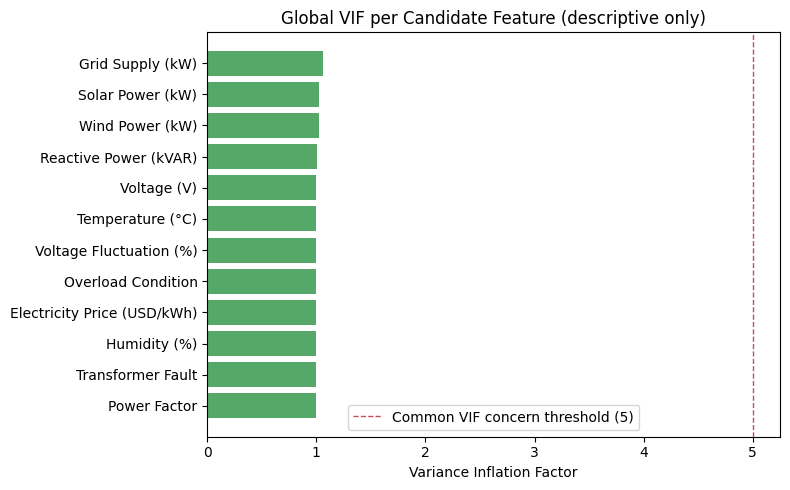

In [34]:
fig, ax = plt.subplots(figsize=(8, 5))
vif_sorted = vif_table.sort_values('VIF')
ax.barh(vif_sorted['feature'], vif_sorted['VIF'], color='#55A868')
ax.axvline(5, color='#C44E52', linestyle='--', linewidth=1, label='Common VIF concern threshold (5)')
ax.set_xlabel('Variance Inflation Factor')
ax.set_title('Global VIF per Candidate Feature (descriptive only)')
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'phase1_vif.png'), dpi=150)
plt.show()

Both tables (and the heatmap/VIF chart above) are reported descriptively in Chapter 5
(dataset characterisation) and are **not** used here to eliminate any feature, consistent
with Chapter 3, Section 3.2: global collinearity does not imply local (within-window)
collinearity in a non-stationary stream, so any action on this diagnostic is deferred to
the windowed feature-selection methods in Phase 5.

## Step 8: Define the candidate feature set

In [35]:
candidate_features = du.get_candidate_features(
    df,
    target_col=du.TARGET_COL,
    exclude_cols=du.IDENTIFIER_COLUMNS + du.LEAKAGE_COLUMNS,
)
print(f'{len(candidate_features)} candidate features:')
for f in candidate_features:
    print(' -', f)

assert candidate_features == du.CANDIDATE_FEATURES, (
    "Computed candidate feature list does not match the CANDIDATE_FEATURES constant "
    "in data_utils.py -- keep these in sync."
)

12 candidate features:
 - Voltage (V)
 - Reactive Power (kVAR)
 - Power Factor
 - Solar Power (kW)
 - Wind Power (kW)
 - Grid Supply (kW)
 - Voltage Fluctuation (%)
 - Overload Condition
 - Transformer Fault
 - Temperature (°C)
 - Humidity (%)
 - Electricity Price (USD/kWh)


### Visualisation: distribution of every candidate feature

A quick shape check across all twelve candidate features — useful for spotting skew, bounded/binary variables (Overload Condition, Transformer Fault), and scale differences before modelling.

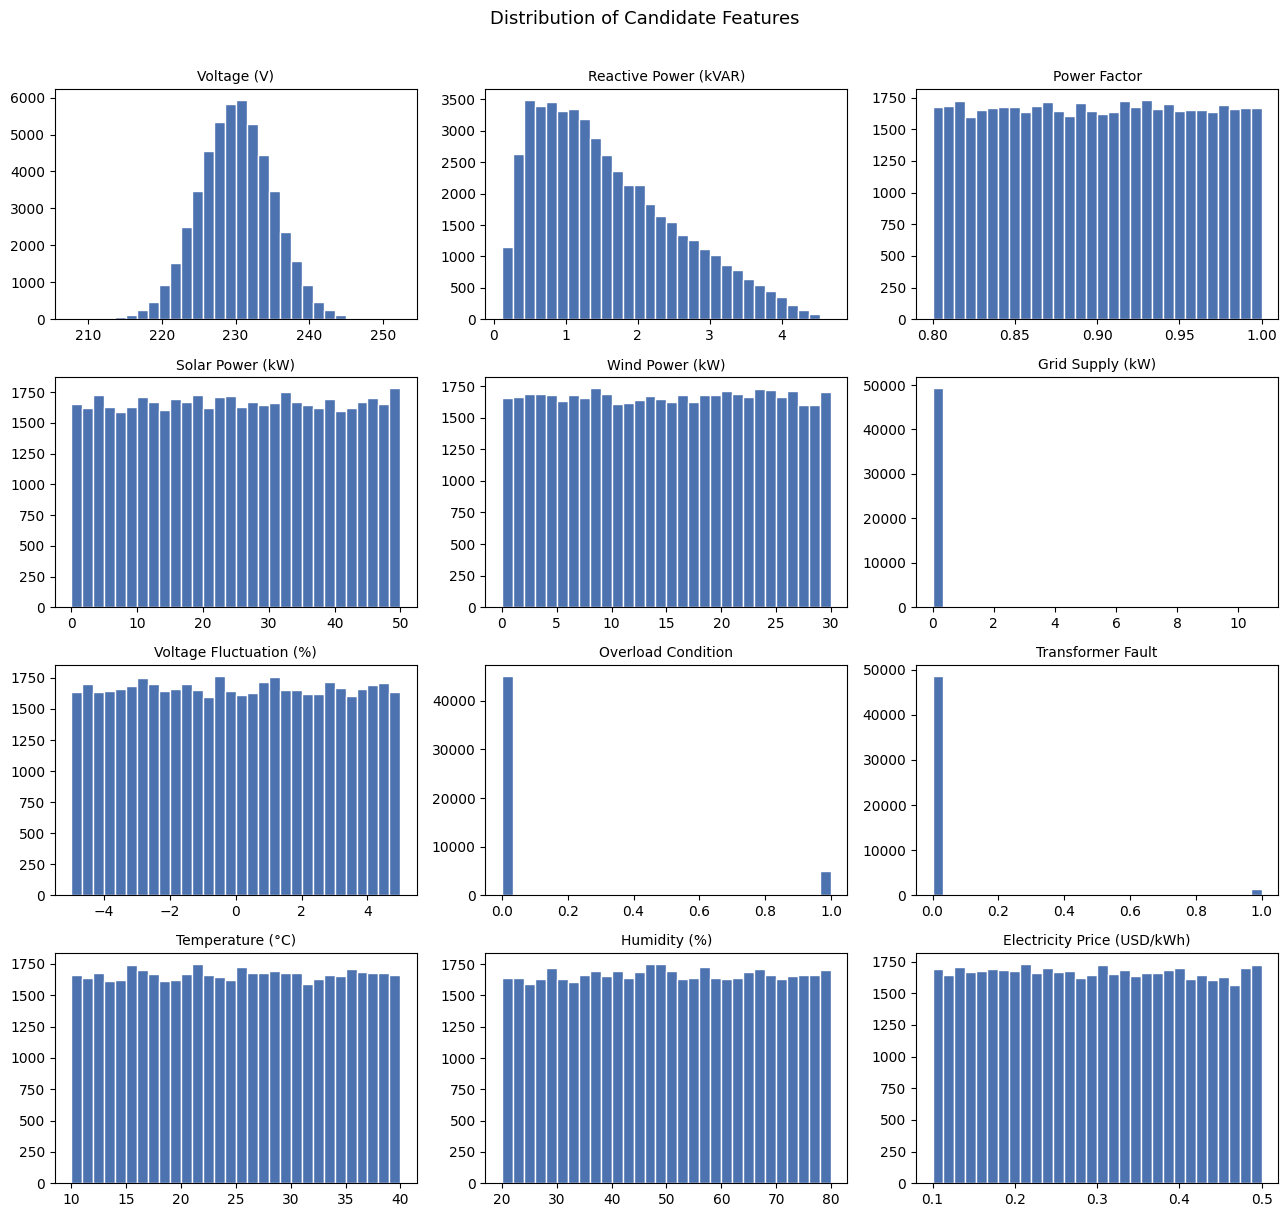

In [36]:
n_features = len(candidate_features)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 3 * n_rows))
axes = axes.flatten()

for i, feat in enumerate(candidate_features):
    axes[i].hist(df[feat], bins=30, color='#4C72B0', edgecolor='white')
    axes[i].set_title(feat, fontsize=10)

for j in range(len(candidate_features), len(axes)):
    axes[j].axis('off')

fig.suptitle('Distribution of Candidate Features', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'phase1_feature_distributions.png'), dpi=150, bbox_inches='tight')
plt.show()

## Step 9: Temporal train/test split and save processed dataset

In [37]:
cols_to_keep = [du.TIMESTAMP_COL] + candidate_features + [du.TARGET_COL]
df_clean = df[cols_to_keep].copy()

train_df, test_df = du.temporal_train_test_split(df_clean, test_size=0.2)
print(f'Train: {len(train_df):,} rows ({train_df[du.TIMESTAMP_COL].min()} → {train_df[du.TIMESTAMP_COL].max()})')
print(f'Test:  {len(test_df):,} rows ({test_df[du.TIMESTAMP_COL].min()} → {test_df[du.TIMESTAMP_COL].max()})')

du.save_processed(df_clean, os.path.join(PROJECT_ROOT, 'data', 'processed', 'smart_grid_clean.csv'))
du.save_processed(train_df, os.path.join(PROJECT_ROOT, 'data', 'processed', 'smart_grid_train.csv'))
du.save_processed(test_df, os.path.join(PROJECT_ROOT, 'data', 'processed', 'smart_grid_test.csv'))
print('\nSaved: smart_grid_clean.csv, smart_grid_train.csv, smart_grid_test.csv')

Train: 40,000 rows (2024-01-01 00:00:00 → 2025-02-20 15:45:00)
Test:  10,000 rows (2025-02-20 16:00:00 → 2025-06-04 19:45:00)

Saved: smart_grid_clean.csv, smart_grid_train.csv, smart_grid_test.csv


### Visualisation: train/test split over time

Confirms visually that the split is a clean chronological cut, not a random shuffle.

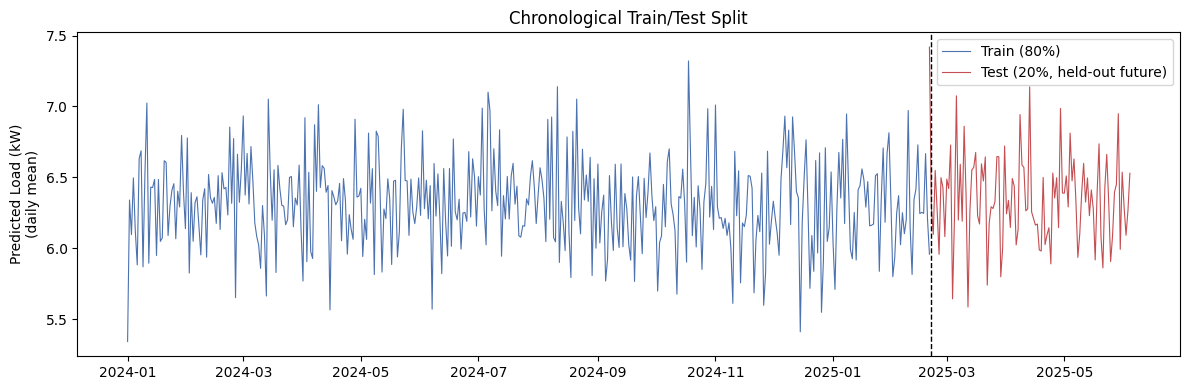

In [38]:
fig, ax = plt.subplots(figsize=(12, 4))
train_daily = train_df.set_index(du.TIMESTAMP_COL)[target].resample('D').mean()
test_daily = test_df.set_index(du.TIMESTAMP_COL)[target].resample('D').mean()

ax.plot(train_daily.index, train_daily.values, color='#4C72B0', label='Train (80%)', linewidth=0.8)
ax.plot(test_daily.index, test_daily.values, color='#C44E52', label='Test (20%, held-out future)', linewidth=0.8)
ax.axvline(train_df[du.TIMESTAMP_COL].max(), color='black', linestyle='--', linewidth=1)
ax.set_ylabel('Predicted Load (kW)\n(daily mean)')
ax.set_title('Chronological Train/Test Split')
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'phase1_train_test_split.png'), dpi=150)
plt.show()

## Summary

| Item | Value |
|---|---|
| Raw rows | 50,000 |
| Candidate features | 12 |
| Excluded (target leakage) | Power Consumption (kW), Current (A) |
| Excluded (identifier) | Timestamp (retained for ordering only) |
| Target | Predicted Load (kW) |
| Missing values | 0 |
| Duplicate rows | 0 |

**Figures produced:** target distribution, target over time (full period + one-week zoom),
target correlation bar chart, candidate feature correlation heatmap, VIF chart, candidate
feature distribution grid, and the train/test split visualisation — all saved to
`results/figures/` for direct use in Chapter 5.

This cleaned, time-ordered dataset (`data/processed/smart_grid_clean.csv`) is the single
shared input to every subsequent phase (02–09).